# **Project 2: Customer Churn Prediction**

Machine Learning — Classification

## **1. Project Description**

Customer Churn Prediction is a Supervised Machine Learning project that aims to predict whether a customer is likely to leave or discontinue a company's services.

In this project, we will use customer information such as tenure, contract type, monthly charges, internet services, payment methods and other account details to identify patterns associated with customer churn.

We will train and compare multiple classification algorithms to predict whether a customer will leave (`Yes`) or stay (`No`).

The goal is to help businesses identify customers who may leave and take appropriate steps to improve customer retention.

## **2. Project Objectives**

- Understand and analyse customer data.
- Perform data cleaning and exploratory data analysis (EDA).
- Identify important factors associated with customer churn.
- Prepare data for Machine Learning.
- Build and compare classification models.
- Evaluate model performance using classification metrics.
- Identify the features that contribute most to churn predictions.

## **3. Dataset Information**

| Detail          | Description              |
| --------------- | ------------------------ |
| Dataset         | IBM Telco Customer Churn |
| Total Records   | 7,043                    |
| Total Columns   | 21                       |
| Target Variable | `Churn`                  |
| Problem Type    | Binary Classification    |
| Output          | Yes / No                 |

## **4. Technologies and Libraries**

- **Python:** Programming language.
- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical computations.
- **Matplotlib & Seaborn:** Data visualization.
- **Scikit-learn:** Model building and evaluation.
- **Joblib:** Saving trained models.

## **5. Machine Learning Algorithms**

We will experiment with:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

## **6. Evaluation Metrics**

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC Score

## **7. Expected Outcome**

A trained Machine Learning classification model capable of predicting customer churn based on customer information.

We will also compare different models, understand their strengths and weaknesses, and identify the factors that influence customer churn predictions.

## **8. Key Concepts We Will Learn**

| Concept               | Purpose                                             |
| --------------------- | --------------------------------------------------- |
| Classification        | Predicting categories                               |
| Binary Classification | Predicting between two classes                      |
| Label Encoding        | Converting categorical labels into numerical values |
| One-Hot Encoding      | Converting categorical features into binary columns |
| Class Imbalance       | Understanding unequal class distribution            |
| Confusion Matrix      | Analysing prediction errors                         |
| Precision & Recall    | Measuring prediction quality                        |
| ROC-AUC               | Measuring classification performance                |
| Feature Importance    | Identifying influential features                    |

**Main learning goal:** By completing this project, we will understand how to build, evaluate and interpret a real-world classification model, expanding our knowledge beyond the regression techniques used in Project 1.

# Importing the libraries

In [1]:
import pandas as pd
import numpy as np

 * Loading the dataset
 - Reading the csv file


In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Inspect the dataset

* Display the first five rows

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


* Check dataset dimensions

In [4]:
df.shape

(7043, 21)

* Check column names

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

# Understanding the data types


* Check data types and non null values

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


* Checking missing values

In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


* Checking blank values

In [8]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

* Display suspiciuos records

In [9]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


* Converting total charges into numerical data

In [10]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

* Filling the missing values

In [11]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

* Verifying the changes

In [12]:
df["TotalCharges"].isnull().sum()

np.int64(0)

* Checking the data type

In [13]:
df["TotalCharges"].dtype

dtype('float64')

# Exploratory Data Analysis

* Checking duplicate records

In [14]:
df.duplicated().sum()

np.int64(0)

* Understanding our target variable
* Calculating their percentages

In [15]:
df["Churn"].value_counts()


,count
Churn,
No,5174
Yes,1869


In [16]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


* Visulaising customer churn

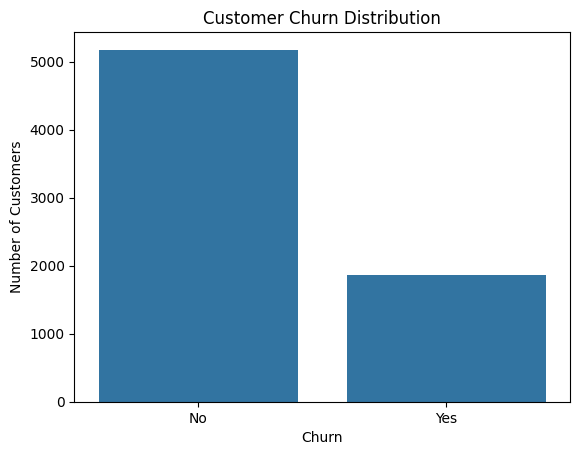

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

 # Exploring numerical features

* Statistical summary

In [18]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


* Comparing tenure with churn

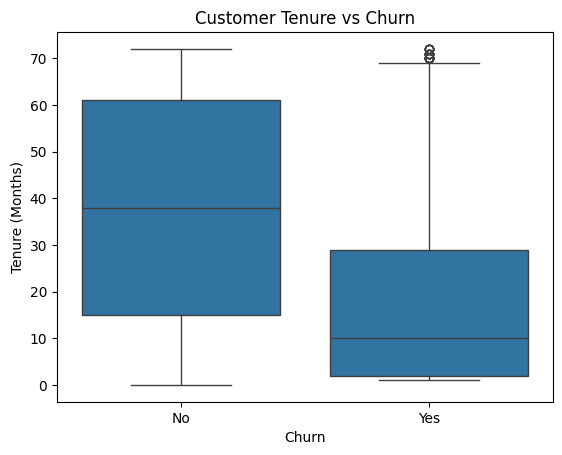

In [19]:
sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

# Exploring categorical features

* Comparing contract type with churn

In [20]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


* Visualize the results

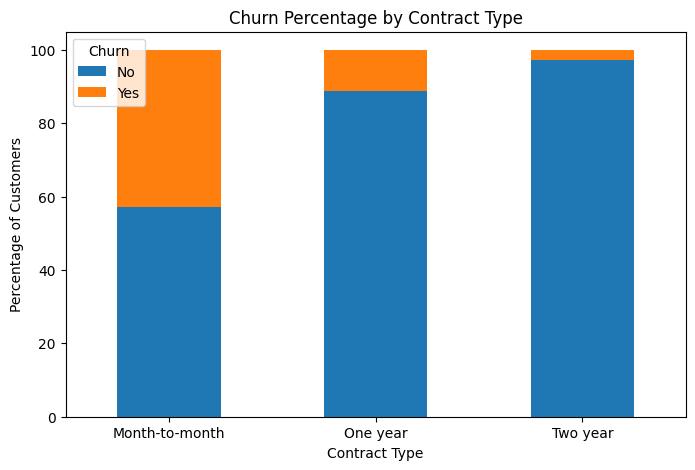

In [21]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.show()

* Payment method vs churn

In [22]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


* Internet services vs churn

In [23]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


* Preparing the data for machine learning

In [24]:
df = df.drop("customerID", axis=1)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


* Seprating input features (X) and target (Y)

In [25]:
# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


* Identifying numerical and categorical features

In [26]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


* Train - test split

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)


* Defining preprocessor snd column transformer

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define preprocessing instructions
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor defined successfully!")
print(preprocessor)

Preprocessor defined successfully!
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


* Transforming the data

In [29]:
# Fit preprocessing on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (5634, 45)
Testing data shape: (1409, 45)


# Training our first model - Logistic regression

In [30]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


* Making predictions

In [31]:
# Predict churn on testing data
y_pred = lr_model.predict(X_test_processed)

print("First 20 predictions:")
print(y_pred[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

First 20 predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


* Calculating evaluating metrics

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664


* Confusion matrix

[[926 109]
 [165 209]]


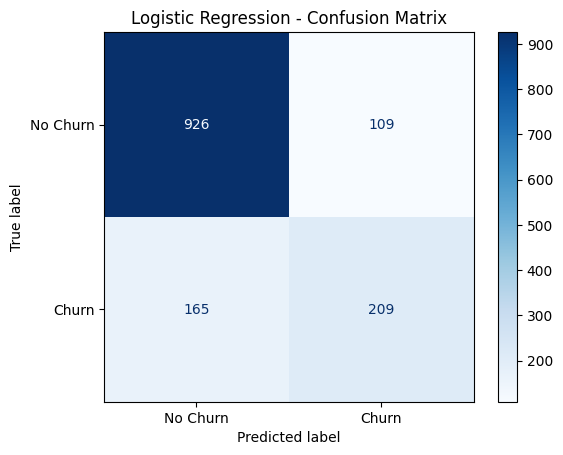

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Training our second model , DECISION TREE

In [34]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


* Making predictions using decision trees

In [35]:
# Predict churn using Decision Tree
dt_pred = dt_model.predict(X_test_processed)

print("First 20 predictions:")
print(dt_pred[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

First 20 predictions:
[0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


* Evaluating the decision trees

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))

Accuracy: 0.7984386089425124
Precision: 0.6347305389221557
Recall: 0.5668449197860963
F1 Score: 0.5988700564971752


# Training the third model , RANDOM FOREST

In [37]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


* Making predictions

In [38]:
# Predict churn using Random Forest
rf_pred = rf_model.predict(X_test_processed)

print("First 20 predictions:")
print(rf_pred[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

First 20 predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


* Evaluating random forest

In [39]:
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

Accuracy: 0.8005677785663591
Precision: 0.658703071672355
Recall: 0.516042780748663
F1 Score: 0.5787106446776612


* Comparing models

In [40]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

print(results.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040
1        Decision Tree    0.7984     0.6347  0.5668    0.5989
2        Random Forest    0.8006     0.6587  0.5160    0.5787


* Visualising the models

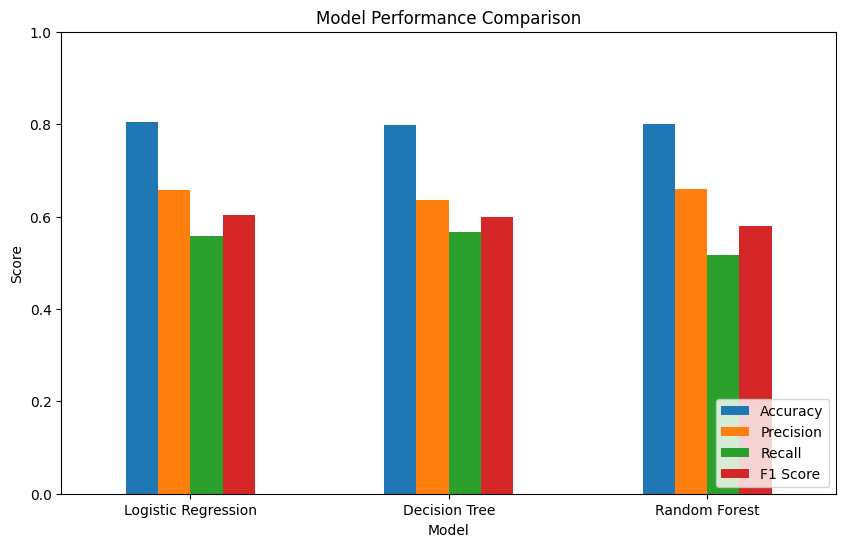

In [41]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

# Handling class imbalance using class weights

In [42]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression with balanced class weights
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
lr_balanced.fit(X_train_processed, y_train)

# Make predictions
lr_balanced_pred = lr_balanced.predict(X_test_processed)

print("Balanced Logistic Regression trained!")

Balanced Logistic Regression trained!


* Evaluating the balanced model

In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Balanced Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, lr_balanced_pred))
print("Precision:", precision_score(y_test, lr_balanced_pred))
print("Recall:", recall_score(y_test, lr_balanced_pred))
print("F1 Score:", f1_score(y_test, lr_balanced_pred))

Balanced Logistic Regression Results
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262


* Inspecting confusion matrix

In [44]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, lr_balanced_pred))

[[747 288]
 [ 81 293]]


* Inspecting prediction probabilities

In [45]:
# Get probability of a customer churning
lr_probabilities = lr_balanced.predict_proba(X_test_processed)[:, 1]

# Display first 10 probabilities
print(lr_probabilities[:10])

[0.11772432 0.85189963 0.14625052 0.66023441 0.06044972 0.80508058
 0.69675764 0.29176099 0.00896026 0.65222865]


* Experimenting with different thresholds

In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    predictions = (lr_probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, predictions), 3))
    print("Recall:", round(recall_score(y_test, predictions), 3))
    print("F1 Score:", round(f1_score(y_test, predictions), 3))


Threshold: 0.3
Precision: 0.43
Recall: 0.928
F1 Score: 0.588

Threshold: 0.4
Precision: 0.466
Recall: 0.866
F1 Score: 0.606

Threshold: 0.5
Precision: 0.504
Recall: 0.783
F1 Score: 0.614

Threshold: 0.6
Precision: 0.54
Recall: 0.706
F1 Score: 0.612


* Comparing all three models at threshold 0.4

In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models_probabilities = {
    "Original Logistic Regression": lr_model.predict_proba(X_test_processed)[:, 1],
    "Balanced Logistic Regression": lr_balanced.predict_proba(X_test_processed)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test_processed)[:, 1]
}

for name, probabilities in models_probabilities.items():
    predictions = (probabilities >= 0.4).astype(int)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("Precision:", round(precision_score(y_test, predictions), 3))
    print("Recall:", round(recall_score(y_test, predictions), 3))
    print("F1 Score:", round(f1_score(y_test, predictions), 3))


Original Logistic Regression
Accuracy: 0.777
Precision: 0.568
Recall: 0.668
F1 Score: 0.614

Balanced Logistic Regression
Accuracy: 0.701
Precision: 0.466
Recall: 0.866
F1 Score: 0.606

Random Forest
Accuracy: 0.779
Precision: 0.573
Recall: 0.652
F1 Score: 0.61


* Understanding ROC AUC

In [48]:
from sklearn.metrics import roc_auc_score

for name, probabilities in models_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)
    print(name, "ROC-AUC:", round(auc, 4))

Original Logistic Regression ROC-AUC: 0.8421
Balanced Logistic Regression ROC-AUC: 0.8416
Random Forest ROC-AUC: 0.8375


* Visualising the ROC curve

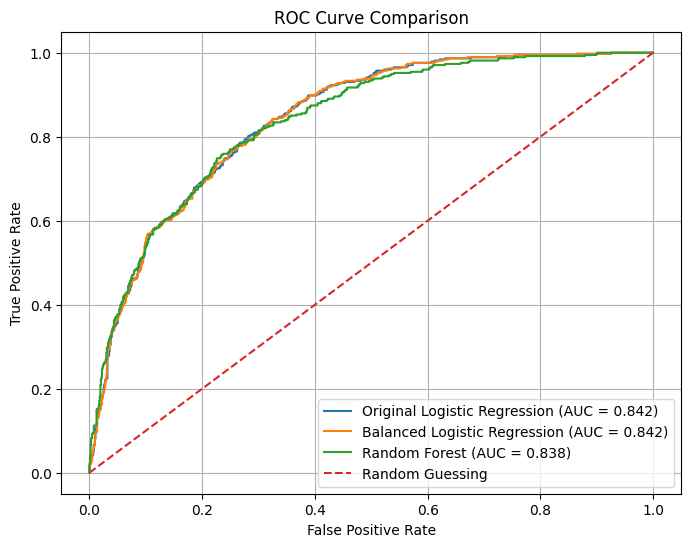

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for name, probabilities in models_probabilities.items():
    fpr, tpr, thresholds_roc = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

* Inspecting the feature importance

In [50]:
import pandas as pd
import numpy as np

feature_names = preprocessor.get_feature_names_out()

coefficients = lr_model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Importance"] = abs(
    feature_importance["Coefficient"]
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print(feature_importance.head(15))

                                      Feature  Coefficient  \
1                                 num__tenure    -1.257539   
38                     cat__Contract_Two year    -0.776594   
15                   cat__InternetService_DSL    -0.648646   
16           cat__InternetService_Fiber optic     0.634195   
2                         num__MonthlyCharges    -0.591863   
36               cat__Contract_Month-to-month     0.582883   
3                           num__TotalCharges     0.536253   
39                   cat__PaperlessBilling_No    -0.343227   
25  cat__DeviceProtection_No internet service    -0.300104   
17                    cat__InternetService_No    -0.300104   
19    cat__OnlineSecurity_No internet service    -0.300104   
28       cat__TechSupport_No internet service    -0.300104   
31       cat__StreamingTV_No internet service    -0.300104   
22      cat__OnlineBackup_No internet service    -0.300104   
34   cat__StreamingMovies_No internet service    -0.300104   

    Abs

* Visualising top 15 coefficients

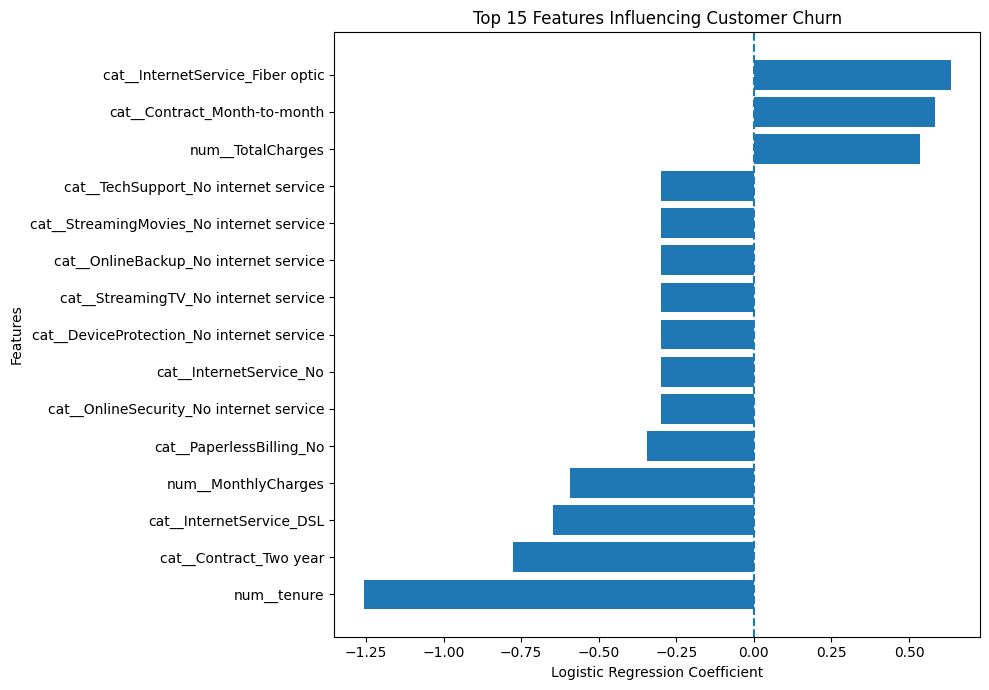

In [51]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Customer Churn")
plt.tight_layout()
plt.show()

# Saving the complete ML pipeline

In [52]:
import joblib
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", lr_model)
])

final_model.fit(X_train, y_train)

joblib.dump(final_model, "customer_churn_model.pkl")

print("Complete Customer Churn Model Saved!")

Complete Customer Churn Model Saved!


# Testing the model on new customer

In [53]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.5,
    "TotalCharges": 171.0
}])

prediction = final_model.predict(new_customer)
probability = final_model.predict_proba(new_customer)[0][1]

print("Churn Prediction:", "Yes" if prediction[0] == 1 else "No")
print("Churn Probability:", round(probability * 100, 2), "%")

Churn Prediction: Yes
Churn Probability: 70.59 %


In [ ]:
# Verifying that our saved model works

In [54]:
import joblib

loaded_model = joblib.load("customer_churn_model.pkl")

loaded_prediction = loaded_model.predict(new_customer)
loaded_probability = loaded_model.predict_proba(new_customer)[0][1]

print("Loaded Model Prediction:",
      "Yes" if loaded_prediction[0] == 1 else "No")

print("Loaded Model Probability:",
      round(loaded_probability * 100, 2), "%")

Loaded Model Prediction: Yes
Loaded Model Probability: 70.59 %


# Creating new file

In [55]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
matplotlib
seaborn
joblib

Writing requirements.txt


* Verifying the file

In [56]:
!cat requirements.txt


pandas
numpy
scikit-learn
matplotlib
seaborn
joblib


# Creating readme.md

In [57]:
%%writefile README.md

# Customer Churn Prediction

## Project Overview
This project uses Machine Learning to predict whether a telecom customer is likely to leave the company (churn) based on customer information, services, contract details, and billing data.

## Dataset
- IBM Telco Customer Churn Dataset
- 7,043 customer records
- 19 input features
- Binary classification target: Churn (Yes/No)

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn
- Google Colab

## Project Workflow
1. Data loading and exploration
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature encoding and scaling
5. Training and comparing classification models
6. Handling class imbalance
7. Threshold tuning
8. Model evaluation using Precision, Recall, F1-score and ROC-AUC
9. Saving and testing the trained model

## Models Evaluated
- Logistic Regression
- Decision Tree
- Random Forest

## Results

Original Logistic Regression:
- Accuracy: 80.55%
- Precision: 65.72%
- Recall: 55.88%
- F1-score: 60.40%
- ROC-AUC: 0.8421

Balanced Logistic Regression:
- Accuracy: 73.81%
- Precision: 50.43%
- Recall: 78.34%
- F1-score: 61.36%
- ROC-AUC: 0.8416

## Key Learnings
- Data cleaning and preprocessing
- Exploratory Data Analysis
- Binary classification
- Handling imbalanced datasets
- Threshold tuning
- Model comparison and evaluation
- Building reusable ML pipelines

## Model Deployment Preparation
The trained Logistic Regression pipeline is saved as `customer_churn_model.pkl`.

It includes preprocessing and prediction in one pipeline and was tested on a new customer record.

## Future Improvements
- Hyperparameter tuning
- Cross-validation
- Further threshold optimization
- Deployment using Flask or FastAPI

## Author
B.Tech Computer Science Engineering Student

Writing README.md


* Verifying readme.md

In [58]:
!cat README.md


# Customer Churn Prediction

## Project Overview
This project uses Machine Learning to predict whether a telecom customer is likely to leave the company (churn) based on customer information, services, contract details, and billing data.

## Dataset
- IBM Telco Customer Churn Dataset
- 7,043 customer records
- 19 input features
- Binary classification target: Churn (Yes/No)

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn
- Google Colab

## Project Workflow
1. Data loading and exploration
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature encoding and scaling
5. Training and comparing classification models
6. Handling class imbalance
7. Threshold tuning
8. Model evaluation using Precision, Recall, F1-score and ROC-AUC
9. Saving and testing the trained model

## Models Evaluated
- Logistic Regression
- Decision Tree
- Random Forest

## Results

Original Logistic Regression:
- Accuracy: 80.55%
- Precision: 65.72%
- R

# Creating .gitignore

In [59]:
%%writefile .gitignore

__pycache__/
*.pyc
.ipynb_checkpoints/
.env
.DS_Store

Writing .gitignore


* Checking the project files

In [60]:
!ls -lah

total 992K
drwxr-xr-x 1 root root 4.0K Nov 22 12:36 .
drwxr-xr-x 1 root root 4.0K Nov 22 11:43 ..
drwxr-xr-x 4 root root 4.0K Nov 18 15:58 .config
-rw-r--r-- 1 root root 7.5K Nov 22 12:25 customer_churn_model.pkl
-rw-r--r-- 1 root root   55 Nov 22 12:36 .gitignore
-rw-r--r-- 1 root root 1.8K Nov 22 12:34 README.md
-rw-r--r-- 1 root root   53 Nov 22 12:32 requirements.txt
drwxr-xr-x 1 root root 4.0K Nov 18 15:58 sample_data
-rw-r--r-- 1 root root 955K Nov 22 11:53 WA_Fn-UseC_-Telco-Customer-Churn.csv
